# Glacier-supported Crop Production Processing & Analysis
The following notebook includes the code that is used to perform analyses to derive the crop production supported by glacier-sourced water. Some figures for the manuscript are included here, while the processed datasets are also used in other jupyter notebooks as well.

Overall, these analyses support a PyGEM-WBM glacier use study.

In [1]:
import os

from tqdm import tqdm

from affine import Affine
import cartopy
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib as mpl
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.path as mpath
import matplotlib.patches as patches
from matplotlib.patches import Patch
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FixedLocator, LogLocator, NullFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
from rasterstats import zonal_stats
import rioxarray
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import uniform_filter
from scipy.spatial import ConvexHull
from scipy.spatial import cKDTree
from shapely.geometry import Point
import xarray as xr

In [2]:
main_directory = os.getcwd()

ssps = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
gcm_names = ['BCC-CSM2-MR', 'CESM2', 'CESM2-WACCM', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-f3-L', 
             'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'MPI-ESM1-2-HR', 'MRI-ESM2-0', 'NorESM2-MM']

# RGI data
rgi_reg_fp = 'rgi_regions/'
rgi_reg_fn = '00_rgi60_O1Regions.shp'

# Plotting details
ssp_name_dict = {'126':'SSP1-2.6',
                 '245':'SSP2-4.5',
                 '370':'SSP3-7.0',
                 '585':'SSP5-8.5',
                 'ssp126':'SSP1-2.6',
                 'ssp245':'SSP2-4.5',
                 'ssp370':'SSP3-7.0',
                 'ssp585':'SSP5-8.5',
                }
ssp_colordict = {'119':'#081d58', '126':'#1d91c0', '245':'#7fcdbb', '370':'#F47A20', '585':'#ED2024',
                'ssp119':'#081d58', 'ssp126':'#1d91c0', 'ssp245':'#7fcdbb', 'ssp370':'#F47A20', 'ssp585':'#ED2024'}

paper_fig_fp = 'figures_paper/'
if not os.path.exists(paper_fig_fp):
    os.makedirs(paper_fig_fp)

min_frac = 0.01

### Rasterized Continents 
Makes subsetting by continents easier & consistent with WBM products

In [3]:
cont_fp = 'ipcc_regions/'
cont_fn = 'IPCC-WGII-continental-regions.geojson'
rasterized_fn = "IPCC-WGII-continental-regions-id.nc"

cont_gdf = gpd.read_file(cont_fp + cont_fn)

if not os.path.exists(cont_fp + rasterized_fn):
    # --- Match CRS (lat/lon assumed WGS84) ---
    cont_gdf = cont_gdf.to_crs("EPSG:4326")
    
    # --- Grid from dataset ---
    lon = ds_irrProd['longitude'].values
    lat = ds_irrProd['latitude'].values  # descending
    
    # --- Resolution ---
    lon_res = lon[1] - lon[0]
    lat_res = lat[1] - lat[0]  # this will be negative
    
    # --- Build transform (note negative y scale) ---
    transform = (
        Affine.translation(lon.min() - lon_res / 2, lat.max() - abs(lat_res) / 2)
        * Affine.scale(lon_res, lat_res)
    )
    
    # --- Prepare shapes ---
    shapes = [
        (geom, value)
        for geom, value in zip(cont_gdf.geometry, cont_gdf['id'])
    ]
    
    # --- Rasterize ---
    raster = rasterize(
        shapes=shapes,
        out_shape=(len(lat), len(lon)),
        transform=transform,
        fill=0,
        dtype='float32'
    )
    
    # --- Create a standalone dataset ---
    ds_conts = xr.Dataset(
        data_vars={
            "cont_id": (("latitude", "longitude"), raster)
        },
        coords={
            "latitude": lat,
            "longitude": lon
        }
    )
    
    # --- Optional: add metadata ---
    ds_conts["cont_id"].attrs["long_name"] = "IPCC continental region ID"
    ds_conts["cont_id"].attrs["description"] = "Rasterized continental IDs from IPCC WGII shapefile"
    
    ds_conts.attrs["source"] = "IPCC-WGII-continental-regions.geojson"
    ds_conts.attrs["crs"] = "EPSG:4326"
    
    # --- Save to NetCDF ---
    ds_conts.to_netcdf(cont_fp + rasterized_fn)
else:
    ds_conts = xr.open_dataset(cont_fp + rasterized_fn)

cont_name2id = dict(zip(cont_gdf["Name"], cont_gdf["id"]))

In [4]:
cont_gdf

,Name,id,Acronym,area,area_land,area_sea,area_mountain,geometry
0,Antarctica,0,ANT,1.233777e+07,1.225232e+07,8.543717e+04,0.000000e+00,"MULTIPOLYGON (((-163.71300 -78.59600, -163.067..."
1,Europe,1,EUR,1.301014e+07,1.264882e+07,3.613626e+05,1.973741e+05,"MULTIPOLYGON (((32.25700 35.10300, 32.49000 34..."
2,Small Islands,2,SMA,9.454662e+05,7.249341e+05,2.205406e+05,0.000000e+00,"MULTIPOLYGON (((-61.20000 -51.85000, -60.70000..."
3,Africa,3,AFR,2.935579e+07,2.887079e+07,4.850495e+05,1.430758e+06,"POLYGON ((34.82300 29.76100, 34.26500 31.21900..."
4,Central and South America,4,CEN,1.835565e+07,1.795328e+07,4.024337e+05,0.000000e+00,"MULTIPOLYGON (((-74.66300 -52.83700, -73.28500..."
5,Australasia,5,AUS,7.964999e+06,7.720186e+06,2.448154e+05,0.000000e+00,"MULTIPOLYGON (((113.33900 -26.11700, 113.47700..."
6,Asia,6,ASI,4.389349e+07,4.287537e+07,1.017953e+06,1.296416e+06,"MULTIPOLYGON (((154.51400 -5.13900, 154.72900 ..."
7,North America,7,NOR,2.149530e+07,2.082931e+07,6.660531e+05,0.000000e+00,"MULTIPOLYGON (((-64.39300 46.72700, -64.14300 ..."


## Elevation data

In [5]:
dem_nc_fn = 'DEM/dem.nc'

if not os.path.exists(dem_nc_fn):
    dem_fn = 'DEM/15min_flwdir_seg_endrh_v2.elvAverg.tif'
    with rasterio.open(dem_fn) as src:
        data = src.read()[0,:,:]
        # Get the affine transformation and dimensions
        transform = src.transform
        height = src.height
        width = src.width
        
        # Create coordinate arrays
        y_coords = np.arange(height) * transform[4] + transform[5] - 0.125  # subtract 0.125 to be consistent with model setup
        x_coords = np.arange(width) * transform[0] + transform[2] + 0.125   # add 0.125 to be consistent with model setup
        bands = np.arange(data.shape[0])  # Band indices
        
        # # Create xarray DataArray
        # da = xr.DataArray(data, dims=('band', 'latitude', 'longitude'), 
        #                         coords={'band': bands,
        #                                 'latitude': y_coords,
        #                                 'longitude': x_coords})
        # Create xarray DataArray
        da = xr.DataArray(data, dims=('latitude', 'longitude'), 
                                coords={'latitude': y_coords,
                                        'longitude': x_coords})
        
    # Convert DataArray to Dataset if needed
    ds_elev = da.to_dataset(name='elev')
    elev_values = ds_elev.elev.values
    elev_values[elev_values<0] = np.nan
    ds_elev['elev'].values = elev_values
    
    ds_elev.to_netcdf(dem_nc_fn)

else:
    ds_elev = xr.open_dataset(dem_nc_fn)

# Irrigation Production - Time Series - by glacier fraction and elevation
- Load data
- Aggregate by continent production
- Multi-GCM median of the continent production per year

In [6]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
min_fracs = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.5]
elev_thresholds = [0, 2500, 3000, 4000]

## Historical

In [7]:
irrProd_fp = 'wbm_data/irrProduction_pg/'
irrProd_fn = 'historical_irrProduction_pg.nc'

irrFrac_fp = 'wbm_data/irr_month_max/'
irrFrac_fn = 'historical_max_GrossIrr_mm_pg_frac.nc'

irrProd_cont_fp = 'processed_data/irrProduction_pg/'
irrProd_cont_fn = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
if not os.path.exists(irrProd_cont_fp + irrProd_cont_fn):

    # Irrigation Production
    ds_irrProd = xr.open_dataset(irrProd_fp + irrProd_fn)

    # Irrigation Fraction
    ds_irrFrac = xr.open_dataset(irrFrac_fp + irrFrac_fn)
    
    # ----- Aggregate by region, fraction, elevation -----
    yrs = list(ds_irrProd.year.values)
    yrs_str = [str(x) for x in yrs]
    df_cns = ['Name', 'elev_threshold', 'frac'] + yrs_str
    cont_irrProd_df = pd.DataFrame(np.zeros((len(rois2plot)*len(min_fracs)*len(elev_thresholds),len(df_cns))), columns=df_cns)
    cont_irrProd_df['Name'] = cont_irrProd_df['Name'].astype(str)
    cont_irrProd_df['elev_threshold'] = cont_irrProd_df['elev_threshold'].astype(int)

    nrow = 0
    for nroi, roi in enumerate(rois2plot):

        # By fraction
        for min_frac in min_fracs:

            # By elevation
            for elev_threshold in elev_thresholds:
                
                if roi in ['Global']:
                    mask = ((ds_irrFrac.max_monthly_frac > min_frac) & 
                            (ds_elev.elev > elev_threshold))
                else:
                    mask = ((ds_irrFrac.max_monthly_frac > min_frac) & 
                            (ds_elev.elev > elev_threshold) &
                            (ds_conts.cont_id == cont_name2id[roi]))

                # Mask and convert to kg (need to multiply by 10^5 to convert to kg)
                irrProd_cont = ds_irrProd.irrProduction_pg.where(mask).sum(dim=('latitude', 'longitude'), skipna=True) * 1e5

                # Record in dataframe
                cont_irrProd_df.loc[nrow,'Name'] = roi
                cont_irrProd_df.loc[nrow,'elev_threshold'] = elev_threshold
                cont_irrProd_df.loc[nrow,'frac'] = min_frac
                cont_irrProd_df.loc[nrow,yrs_str] = irrProd_cont
                
                nrow += 1

    # Export
    if not os.path.exists(irrProd_cont_fp):
        os.makedirs(irrProd_cont_fp)
    cont_irrProd_df.to_csv(irrProd_cont_fp + irrProd_cont_fn, index=False)

else:
    # Load data
    cont_irrProd_df = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn)

In [8]:
cont_irrProd_df.head()

,Name,elev_threshold,frac,1980,1981,1982,1983,1984,1985,1986,...,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
0,Global,0,0.01,7.897380e+08,7.149811e+08,6.036398e+08,5.861933e+08,8.961330e+08,9.501692e+08,7.726825e+08,...,1.426055e+09,1.595711e+09,1.599452e+09,1.181036e+09,9.619844e+08,9.672982e+08,1.207321e+09,1.245970e+09,1.276497e+09,1.340203e+09
1,Global,2500,0.01,4.696165e+05,1.605323e+05,2.926153e+05,1.080591e+06,7.909474e+05,4.966256e+05,6.150934e+05,...,2.696831e+06,4.873782e+06,6.189738e+06,3.728472e+06,5.340324e+06,4.001021e+06,3.904833e+06,6.079813e+06,4.294018e+06,5.705194e+06
2,Global,3000,0.01,3.333315e+05,1.057595e+05,1.397738e+05,8.448508e+05,3.668093e+05,1.535278e+05,1.627007e+05,...,1.321072e+06,2.881716e+06,3.219417e+06,2.196816e+06,4.115933e+06,2.180162e+06,2.259410e+06,3.596252e+06,2.107787e+06,3.290934e+06
3,Global,4000,0.01,8.755101e+02,7.263173e+02,1.050453e+03,2.426590e+05,1.783316e+05,5.816022e+02,4.083621e+04,...,4.154085e+05,1.090908e+06,1.249978e+06,1.117389e+06,2.369424e+06,9.707794e+05,1.224953e+06,2.437908e+06,9.196361e+05,1.555678e+06
4,Global,0,0.05,6.152278e+08,4.549709e+08,3.860905e+08,4.079201e+08,7.098631e+08,7.701645e+08,5.235417e+08,...,1.176662e+09,1.387289e+09,1.376804e+09,9.132808e+08,6.368628e+08,6.696639e+08,9.396843e+08,9.742564e+08,9.502926e+08,9.833484e+08


#### Present-day values for manuscript

In [9]:
crop_df = cont_irrProd_df
yr_cns = [str(x) for x in range(2006,2016)]

crop_global_2006_2015 = cont_irrProd_df.loc[(crop_df['Name'] == 'Global') & 
                                            (crop_df['elev_threshold'] == 0) & 
                                            (crop_df['frac'] == 0.01), yr_cns].values[0,:].mean()
crop_asia_2006_2015 = cont_irrProd_df.loc[(crop_df['Name'] == 'Asia') & 
                                          (crop_df['elev_threshold'] == 0) & 
                                          (crop_df['frac'] == 0.01), yr_cns].values[0,:].mean()

print('Global mean (2006-2015) 10^6 tonnes:', np.round(crop_global_2006_2015/1e9,2))
print('Asia mean (2006-2015) 10^6 tonnes:', np.round(crop_asia_2006_2015/1e9,2))
print('Percent Asia:', np.round(100*crop_asia_2006_2015 / crop_global_2006_2015,0))

Global mean (2006-2015) 10^6 tonnes: 1.28
Asia mean (2006-2015) 10^6 tonnes: 1.05
Percent Asia: 82.0


## Future

In [10]:
irrProd_fp = 'wbm_data/irrProduction_pg/'
irrFrac_fp = 'wbm_data/irr_month_max/'

irrProd_cont_fp_gcms = 'processed_data/irrProduction_pg/individual_gcms/'
for nssp, ssp in enumerate(ssps):
    
    for ngcm, gcm_name in enumerate(gcm_names):

        irrProd_cont_fn = gcm_name + '_' + ssp + '_continents_irrProduction_pg_kg-byfrac-byelev.csv'

        if not os.path.exists(irrProd_cont_fp_gcms + irrProd_cont_fn):

            print(ssp, gcm_name)

            # Irrigation Production
            irrProd_fn = gcm_name + '_' + ssp + '_irrProduction_pg.nc'
            ds_irrProd = xr.open_dataset(irrProd_fp + irrProd_fn)

            # Irrigation Fraction
            irrFrac_fn = gcm_name + '_' + ssp + '_max_GrossIrr_mm_pg_frac.nc'
            ds_irrFrac = xr.open_dataset(irrFrac_fp + irrFrac_fn)
            
            # ----- Aggregate by region, fraction, elevation -----
            yrs = list(ds_irrProd.year.values)
            yrs_str = [str(x) for x in yrs]
            df_cns = ['Name', 'elev_threshold', 'frac'] + yrs_str
            cont_irrProd_df = pd.DataFrame(np.zeros((len(rois2plot)*len(min_fracs)*len(elev_thresholds),len(df_cns))), columns=df_cns)
            cont_irrProd_df['Name'] = cont_irrProd_df['Name'].astype(str)
            cont_irrProd_df['elev_threshold'] = cont_irrProd_df['elev_threshold'].astype(int)


            nrow = 0
            for nroi, roi in enumerate(rois2plot):

                print(roi)
        
                # By fraction
                for min_frac in min_fracs:
        
                    # By elevation
                    for elev_threshold in elev_thresholds:
                        
                        if roi in ['Global']:
                            mask = ((ds_irrFrac.max_monthly_frac > min_frac) & 
                                    (ds_elev.elev > elev_threshold))
                        else:
                            mask = ((ds_irrFrac.max_monthly_frac > min_frac) & 
                                    (ds_elev.elev > elev_threshold) &
                                    (ds_conts.cont_id == cont_name2id[roi]))
        
                        # Mask and convert to kg (need to multiply by 10^5 to convert to kg)
                        irrProd_cont = ds_irrProd.irrProduction_pg.where(mask).sum(dim=('latitude', 'longitude'), skipna=True) * 1e5

                        # Record in dataframe
                        cont_irrProd_df.loc[nrow,'Name'] = roi
                        cont_irrProd_df.loc[nrow,'elev_threshold'] = elev_threshold
                        cont_irrProd_df.loc[nrow,'frac'] = min_frac
                        cont_irrProd_df.loc[nrow,yrs_str] = irrProd_cont
                        
                        nrow += 1
   
            # Export dataframe
            if not os.path.exists(irrProd_cont_fp_gcms):
                os.makedirs(irrProd_cont_fp_gcms)
            cont_irrProd_df.to_csv(irrProd_cont_fp_gcms + irrProd_cont_fn, index=False)


In [11]:
# cont_irrProd_df

## Multi-GCM medians

In [12]:
yr_cns = [str(x) for x in range(2016,2100)]
for nssp, ssp in enumerate(ssps):

    irrProd_cont_fn_med = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'

    if not os.path.exists(irrProd_cont_fp + irrProd_cont_fn_med):
    
        for ngcm, gcm_name in enumerate(gcm_names):

            print(ssp, gcm_name)

            irrProd_cont_fn = gcm_name + '_' + ssp + '_continents_irrProduction_pg_kg-byfrac-byelev.csv'

            cont_irrProd_df = pd.read_csv(irrProd_cont_fp_gcms + irrProd_cont_fn)

            if ngcm == 0:
                # Save to check file structure in other files
                check_cns = ['Name', 'elev_threshold', 'frac']
                df1 = cont_irrProd_df
    
                # Save data
                values_all = cont_irrProd_df.loc[:,yr_cns].values[np.newaxis,:,:]
    
            else:
                # Check file structure is the same
                assert df1.loc[:, check_cns].equals(cont_irrProd_df.loc[:, check_cns]), 'check that file structure is the same'
    
                # Append each GCM
                values_all = np.concatenate((values_all, cont_irrProd_df.loc[:,yr_cns].values[np.newaxis,:,:]), axis=0)
    
        values_med = np.median(values_all, axis=0)
    
        cont_irrProd_df_med = cont_irrProd_df.copy()
        cont_irrProd_df_med.loc[:,yr_cns] = values_med

        # Export file
        cont_irrProd_df_med.to_csv(irrProd_cont_fp + irrProd_cont_fn_med, index=False)


#### Future values for manuscript

In [13]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

print('max crop production')

for roi in rois2plot:
    print('\n')

    # Change relative to present
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yr_hist_cns = [str(x) for x in range(2006,2016)]

    crops_2006s = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                   (crop_df_hist['elev_threshold'] == 0) & 
                                   (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:].mean()
    
    print('2006-2015', roi, np.round(crops_2006s/1e9,3))
    
    for ssp in ssps:
    
        irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'

        yr_cns = [str(x) for x in range(2016,2100)]
        
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)
        crop_values = crop_df.loc[(crop_df['Name'] == roi) & 
                                  (crop_df['elev_threshold'] == 0) & 
                                  (crop_df['frac'] == 0.01), yr_cns].values[0,:]

        # Max crops
        max_idx = np.where(crop_values == crop_values.max())[0][0]
        
        print(ssp, roi, yr_cns[max_idx], np.round(crop_values[max_idx]/1e9,3))

        # End of century
        crops_2090s = crop_values[-10:].mean()
        print(ssp, roi, '  2090-2099', np.round(crops_2090s/1e9,3))

        print(ssp, roi, 'change:', str(np.round(100*(crops_2090s/crops_2006s),1)) + '%')

max crop production


2006-2015 Global 1.28
ssp126 Global 2026 1.49
ssp126 Global   2090-2099 0.546
ssp126 Global change: 42.6%
ssp245 Global 2028 1.713
ssp245 Global   2090-2099 0.547
ssp245 Global change: 42.7%
ssp370 Global 2022 1.51
ssp370 Global   2090-2099 0.624
ssp370 Global change: 48.7%
ssp585 Global 2051 1.703
ssp585 Global   2090-2099 0.503
ssp585 Global change: 39.3%


2006-2015 Asia 1.049
ssp126 Asia 2027 1.266
ssp126 Asia   2090-2099 0.5
ssp126 Asia change: 47.7%
ssp245 Asia 2028 1.447
ssp245 Asia   2090-2099 0.525
ssp245 Asia change: 50.1%
ssp370 Asia 2058 1.275
ssp370 Asia   2090-2099 0.586
ssp370 Asia change: 55.9%
ssp585 Asia 2051 1.53
ssp585 Asia   2090-2099 0.492
ssp585 Asia change: 46.9%


2006-2015 Europe 0.179
ssp126 Europe 2017 0.231
ssp126 Europe   2090-2099 0.032
ssp126 Europe change: 17.6%
ssp245 Europe 2022 0.241
ssp245 Europe   2090-2099 0.014
ssp245 Europe change: 7.6%
ssp370 Europe 2023 0.207
ssp370 Europe   2090-2099 0.013
ssp370 Europe change: 7.3%
ssp5

### By percent values for manuscript

In [14]:
# Change relative to present
irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
yr_hist_cns = [str(x) for x in range(2006,2016)]

roi = 'Global'
for yr_start in [2006, 2050, 2090]:

    if yr_start in [2006]:

        for frac in [0.01, 0.1, 0.25, 0.5]:
            
            crops_2006s = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                           (crop_df_hist['elev_threshold'] == 0) & 
                                           (crop_df_hist['frac'] == frac), yr_hist_cns].values[0,:].mean()
        
            print(roi, '2006-2015', str(int(frac*100)) + '%', np.round(crops_2006s/1e9,3))

    else:

        print('\n')
        for ssp in ssps:
        
            irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
    
            yr_cns = [str(x) for x in range(2016,2100)]
            
            crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)
    
            decade_cns = [str(x) for x in range(yr_start, yr_start+10)]

            for frac in [0.01, 0.1, 0.25, 0.5]:
            
                crop_mean = crop_df.loc[(crop_df['Name'] == roi) & 
                                          (crop_df['elev_threshold'] == 0) & 
                                          (crop_df['frac'] == frac), decade_cns].values[0,:].mean()

                print(roi, ssp, str(yr_start) + '-' + str(yr_start+10), str(int(frac*100)) + '%', np.round(crop_mean/1e9,3))
        

Global 2006-2015 1% 1.28
Global 2006-2015 10% 0.572
Global 2006-2015 25% 0.086
Global 2006-2015 50% 0.002


Global ssp126 2050-2060 1% 1.115
Global ssp126 2050-2060 10% 0.374
Global ssp126 2050-2060 25% 0.045
Global ssp126 2050-2060 50% 0.0
Global ssp245 2050-2060 1% 1.193
Global ssp245 2050-2060 10% 0.426
Global ssp245 2050-2060 25% 0.072
Global ssp245 2050-2060 50% 0.002
Global ssp370 2050-2060 1% 1.375
Global ssp370 2050-2060 10% 0.551
Global ssp370 2050-2060 25% 0.117
Global ssp370 2050-2060 50% 0.009
Global ssp585 2050-2060 1% 1.433
Global ssp585 2050-2060 10% 0.622
Global ssp585 2050-2060 25% 0.145
Global ssp585 2050-2060 50% 0.002


Global ssp126 2090-2100 1% 0.546
Global ssp126 2090-2100 10% 0.088
Global ssp126 2090-2100 25% 0.007
Global ssp126 2090-2100 50% 0.0
Global ssp245 2090-2100 1% 0.547
Global ssp245 2090-2100 10% 0.195
Global ssp245 2090-2100 25% 0.026
Global ssp245 2090-2100 50% 0.0
Global ssp370 2090-2100 1% 0.624
Global ssp370 2090-2100 10% 0.29
Global ssp370 2090-2

## Irrigation Production time series plot: totals

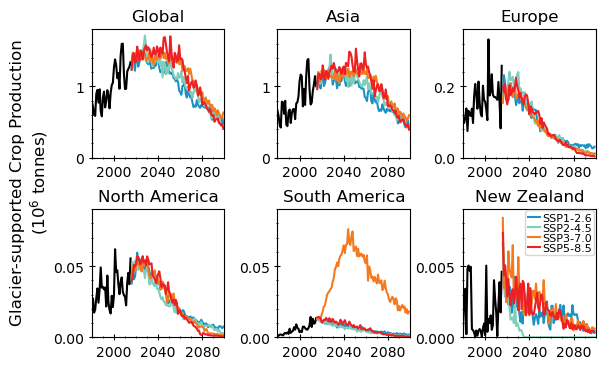

In [15]:
ssps2plot = ['ssp126', 'ssp245', 'ssp370', 'ssp585']

rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(6.5, 4), gridspec_kw={'hspace': 0.4, 'wspace':0.4})
axs = axs.flatten()  # make indexing easier

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    # ----- Historical -----
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yrs_hist = range(1980,2016)
    yr_hist_cns = [str(x) for x in yrs_hist]

    crop_values_hist = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                        (crop_df_hist['elev_threshold'] == 0) & 
                                        (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:]
    # crop_values_hist_movingavg = uniform_filter(crop_values_hist, size=(11), mode='nearest')

    ax.plot(yrs_hist, crop_values_hist/1e9, color='k')

    # ----- Future -----
    for ssp in ssps2plot:

        irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'

        yrs = range(2016,2100)
        yr_cns = [str(x) for x in yrs]
        
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)
        crop_values = crop_df.loc[(crop_df['Name'] == roi) & 
                                  (crop_df['elev_threshold'] == 0) & 
                                  (crop_df['frac'] == 0.01), yr_cns].values[0,:]
        # crop_values_movingavg = uniform_filter(crop_values, size=(11), mode='nearest')
    
        ax.plot(yrs, crop_values/1e9, linestyle='-', color=ssp_colordict[ssp])

    
    # ----- LABELS/FORMATING -----
    ax.set_xlim(1980, 2100)
    
    # ax.grid(True)
    # ax.set_ylim(1e2,2e6)
    # ax.set_yscale('log')
    # ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    # ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks

    if roi in ['Global', 'Asia']:
        ax.set_ylim(0,1.8)
        ax.yaxis.set_major_locator(MultipleLocator(1)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.2))
    elif roi in ['Europe']:
        ax.set_ylim(0,0.36)
        ax.yaxis.set_major_locator(MultipleLocator(0.2)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.04))
    elif roi in ['North America', 'Central and South America']:
        ax.set_ylim(0,0.09)
        ax.yaxis.set_major_locator(MultipleLocator(0.05)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.01))
    elif roi in ['Australasia']:
        ax.set_ylim(0,0.009)
        ax.yaxis.set_major_locator(MultipleLocator(0.005)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.001))
    else:
        ax.set_ylim(0,0.0006)
    
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.xaxis.set_major_locator(MultipleLocator(40))  # Major ticks every 25
    ax.xaxis.set_minor_locator(MultipleLocator(10))    # Minor ticks every 5
    ax.tick_params(axis='both', which='major', direction='inout', length=4)
    ax.tick_params(axis='both', which='minor', direction='inout', length=2)

    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)

    if roi in ['Australasia']:
        legend_elements = []
        for ssp in ssps2plot:
            legend_elements.append(Line2D([0], [0], color=ssp_colordict[ssp], linestyle='-', label=ssp_name_dict[ssp]))
        # for nfrac, frac2plot in enumerate(fracs2plot):
        #     legend_elements.append(Line2D([0], [0], color='grey', linestyle=fracs2plot_linestyles[nfrac], 
        #                                   label='>' + str(int(fracs2plot[nfrac]*100)) + '%', linewidth=1))
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.0, handlelength=1.1, handletextpad=0.2, ncol=1,
                  loc="upper right", bbox_to_anchor=(0.99, 0.99), 
                  borderaxespad=0.01, borderpad=0.2, columnspacing=0.75)

fig.supylabel('Glacier-supported Crop Production\n(10$^{6}$ tonnes)', x=0.03, size=12, va='center', ha='center')
fig.savefig(paper_fig_fp + 'continent_irrProd_timeseries-horz.png', bbox_inches='tight', dpi=300)
plt.show()

## Irrigation production time series plot: by fraction

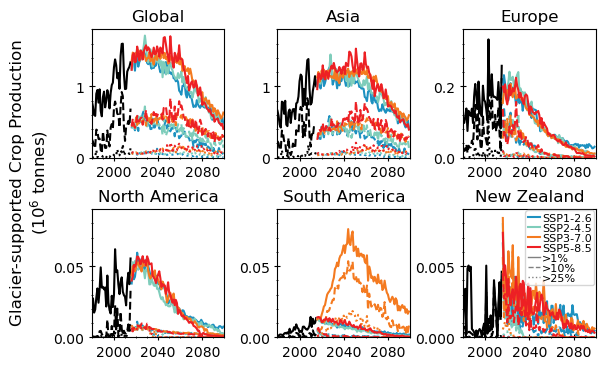

In [16]:
ssps2plot = ['ssp126', 'ssp245', 'ssp370', 'ssp585']

rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
fracs2plot = [0.01, 0.1, 0.25]
fracs2plot_linestyles = ['-', '--', ':']

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(6.5, 4), gridspec_kw={'hspace': 0.4, 'wspace':0.4})
axs = axs.flatten()  # make indexing easier

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    # ----- Historical -----
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yrs_hist = range(1980,2016)
    yr_hist_cns = [str(x) for x in yrs_hist]

    for nfrac, frac2plot in enumerate(fracs2plot):
        crop_values_hist = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                            (crop_df_hist['elev_threshold'] == 0) & 
                                            (crop_df_hist['frac'] == frac2plot), yr_hist_cns].values[0,:]
        # crop_values_hist_movingavg = uniform_filter(crop_values_hist, size=(11), mode='nearest')
        
        ax.plot(yrs_hist, crop_values_hist/1e9, color='k', linestyle=fracs2plot_linestyles[nfrac])

    # ----- Future -----
    for ssp in ssps2plot:

        irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'

        yrs = range(2016,2100)
        yr_cns = [str(x) for x in yrs]
        
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)
        
        for nfrac, frac2plot in enumerate(fracs2plot):
            crop_values = crop_df.loc[(crop_df['Name'] == roi) & 
                                      (crop_df['elev_threshold'] == 0) & 
                                      (crop_df['frac'] == frac2plot), yr_cns].values[0,:]
            # crop_values_movingavg = uniform_filter(crop_values, size=(11), mode='nearest')
            
            ax.plot(yrs, crop_values/1e9, color=ssp_colordict[ssp], linestyle=fracs2plot_linestyles[nfrac])
    
    # ----- LABELS/FORMATING -----
    ax.set_xlim(1980, 2100)
    
    # ax.grid(True)
    # ax.set_ylim(1e2,2e6)
    # ax.set_yscale('log')
    # ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    # ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks

    if roi in ['Global', 'Asia']:
        ax.set_ylim(0,1.8)
        ax.yaxis.set_major_locator(MultipleLocator(1)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.2))
    elif roi in ['Europe']:
        ax.set_ylim(0,0.36)
        ax.yaxis.set_major_locator(MultipleLocator(0.2)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.04))
    elif roi in ['North America', 'Central and South America']:
        ax.set_ylim(0,0.09)
        ax.yaxis.set_major_locator(MultipleLocator(0.05)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.01))
    elif roi in ['Australasia']:
        ax.set_ylim(0,0.009)
        ax.yaxis.set_major_locator(MultipleLocator(0.005)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.001))
    else:
        ax.set_ylim(0,0.0006)
    
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.xaxis.set_major_locator(MultipleLocator(40))  # Major ticks every 25
    ax.xaxis.set_minor_locator(MultipleLocator(10))    # Minor ticks every 5
    ax.tick_params(axis='both', which='major', direction='inout', length=4)
    ax.tick_params(axis='both', which='minor', direction='inout', length=2)

    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)

    if roi in ['Australasia']:
        legend_elements = []
        for ssp in ssps2plot:
            legend_elements.append(Line2D([0], [0], color=ssp_colordict[ssp], linestyle='-', label=ssp_name_dict[ssp]))
        for nfrac, frac2plot in enumerate(fracs2plot):
            legend_elements.append(Line2D([0], [0], color='grey', linestyle=fracs2plot_linestyles[nfrac], 
                                          label='>' + str(int(fracs2plot[nfrac]*100)) + '%', linewidth=1))
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.0, handlelength=1.1, handletextpad=0.2, ncol=1,
                  loc="upper right", bbox_to_anchor=(0.99, 0.99), 
                  borderaxespad=0.01, borderpad=0.2, columnspacing=0.75)

fig.supylabel('Glacier-supported Crop Production\n(10$^{6}$ tonnes)', x=0.03, size=12, va='center', ha='center')
fig.savefig(paper_fig_fp + 'continent_irrProd_timeseries-horz-byfrac.png', bbox_inches='tight', dpi=300)
plt.show()

## Irrigation production time series plot: by fraction - moving average to smooth variability
The key difference is that the historical and the futures are merged together to make the moving average smooth.

The historical is represented via averaging with SSP2-4.5

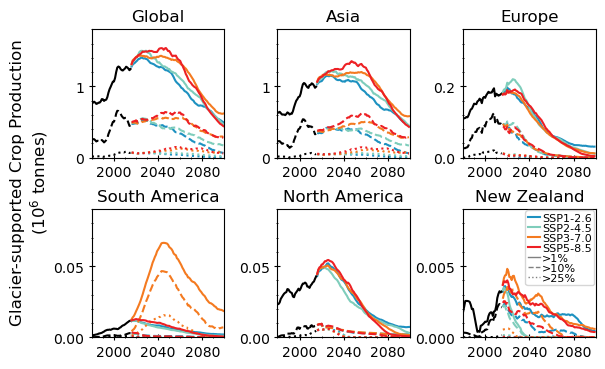

In [17]:
ssps2plot = ['ssp126', 'ssp245', 'ssp370', 'ssp585']

rois2plot = ['Global', 'Asia', 'Europe', 'Central and South America', 'North America', 'Australasia']
fracs2plot = [0.01, 0.1, 0.25]
fracs2plot_linestyles = ['-', '--', ':']

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(6.5, 4), gridspec_kw={'hspace': 0.4, 'wspace':0.4})
axs = axs.flatten()  # make indexing easier

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    # ----- Merge Historical and Future together to get smooth moving averages ----
    # ----- Historical -----
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yrs_hist = range(1980,2016)
    yr_hist_cns = [str(x) for x in yrs_hist]

    for ssp in ssps2plot:
        # ----- Future -----
        irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
        yrs = range(2016,2100)
        yr_cns = [str(x) for x in yrs]
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)
        
        for nfrac, frac2plot in enumerate(fracs2plot):
            crop_values_hist = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                                (crop_df_hist['elev_threshold'] == 0) & 
                                                (crop_df_hist['frac'] == frac2plot), yr_hist_cns].values[0,:]
            crop_values = crop_df.loc[(crop_df['Name'] == roi) & 
                                      (crop_df['elev_threshold'] == 0) & 
                                      (crop_df['frac'] == frac2plot), yr_cns].values[0,:]
            
            crop_values_hist_wssp = np.concatenate((crop_values_hist, crop_values))
            crop_values_hist_wssp_movingavg = uniform_filter(crop_values_hist_wssp, size=(11), mode='nearest')
    
            if ssp in ['ssp245']:
                ax.plot(range(1980,2016), crop_values_hist_wssp_movingavg[0:crop_values_hist.shape[0]]/1e9, 
                        color='k', linestyle=fracs2plot_linestyles[nfrac])
                
            ax.plot(range(2016,2100), crop_values_hist_wssp_movingavg[crop_values_hist.shape[0]:]/1e9, 
                    color=ssp_colordict[ssp], linestyle=fracs2plot_linestyles[nfrac])

    # ----- LABELS/FORMATING -----
    ax.set_xlim(1980, 2100)
    
    # ax.grid(True)
    # ax.set_ylim(1e2,2e6)
    # ax.set_yscale('log')
    # ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    # ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks

    if roi in ['Global', 'Asia']:
        ax.set_ylim(0,1.8)
        ax.yaxis.set_major_locator(MultipleLocator(1)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.2))
    elif roi in ['Europe']:
        ax.set_ylim(0,0.36)
        ax.yaxis.set_major_locator(MultipleLocator(0.2)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.04))
    elif roi in ['North America', 'Central and South America']:
        ax.set_ylim(0,0.09)
        ax.yaxis.set_major_locator(MultipleLocator(0.05)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.01))
    elif roi in ['Australasia']:
        ax.set_ylim(0,0.009)
        ax.yaxis.set_major_locator(MultipleLocator(0.005)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.001))
    else:
        ax.set_ylim(0,0.0006)
    
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.xaxis.set_major_locator(MultipleLocator(40))  # Major ticks every 25
    ax.xaxis.set_minor_locator(MultipleLocator(10))    # Minor ticks every 5
    ax.tick_params(axis='both', which='major', direction='inout', length=4)
    ax.tick_params(axis='both', which='minor', direction='inout', length=2)

    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)

    if roi in ['Australasia']:
        legend_elements = []
        for ssp in ssps2plot:
            legend_elements.append(Line2D([0], [0], color=ssp_colordict[ssp], linestyle='-', label=ssp_name_dict[ssp]))
        for nfrac, frac2plot in enumerate(fracs2plot):
            legend_elements.append(Line2D([0], [0], color='grey', linestyle=fracs2plot_linestyles[nfrac], 
                                          label='>' + str(int(fracs2plot[nfrac]*100)) + '%', linewidth=1))
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.0, handlelength=1.1, handletextpad=0.2, ncol=1,
                  loc="upper right", bbox_to_anchor=(0.99, 0.99), 
                  borderaxespad=0.01, borderpad=0.2, columnspacing=0.75)

fig.supylabel('Glacier-supported Crop Production\n(10$^{6}$ tonnes)', x=0.03, size=12, va='center', ha='center')
fig.savefig(paper_fig_fp + 'fig4-continent_irrProd_timeseries-horz-byfrac_movingavg.png', bbox_inches='tight', dpi=300)
plt.show()

# Decadal Averages for Tables

In [18]:
rois = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

df_cns = ['1%', '10%', '20%', '50%', '2500 m']
df_cns_frac_elev_dict = {'1%':[0.01, 0],
                         '5%':[0.05, 0],
                         '10%':[0.10, 0],
                         '20%':[0.20, 0],
                         '50%':[0.50, 0],
                         '2500 m':[0.01, 2500]}
ssp_name_dict_inverted = {v: k for k, v in ssp_name_dict.items()}

periods = ['2006-2015', 
           'SSP1-2.6 2050-2059', 'SSP1-2.6 2090-2099',
           'SSP2-4.5 2050-2059', 'SSP2-4.5 2090-2099',
           'SSP3-7.0 2050-2059', 'SSP3-7.0 2090-2099',
           'SSP5-8.5 2050-2059', 'SSP5-8.5 2090-2099']

output_df = pd.DataFrame(np.zeros((len(periods)*len(rois), 3+len(df_cns))), columns = ['Region', 'SSP', 'Period'] + df_cns)
output_df['Region'] = output_df['Region'].astype(str)
output_df['SSP'] = output_df['SSP'].astype(str)
output_df['Period'] = output_df['Period'].astype(str)

nrow = 0
for roi in rois:
    
    for period in periods:

        output_df.loc[nrow,'Region'] = roi

        # Historical
        if period in ['2006-2015']:

            irrProd_cont_fn = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
            yr_start = int(period.split('-')[0])
            yr_cns = [str(x) for x in range(yr_start, yr_start+10)]
            output_df.loc[nrow, 'SSP'] = 'historical'
            output_df.loc[nrow, 'Period'] = period

        # SSP & time period
        else:
            
            ssp_cap, yrs = period.split(' ')
            ssp = ssp_name_dict_inverted[ssp_cap]
            yr_start = int(yrs.split('-')[0])
            yr_cns = [str(x) for x in range(yr_start, yr_start+10)]
            irrProd_cont_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
            output_df.loc[nrow, 'SSP'] = ssp_cap
            output_df.loc[nrow, 'Period'] = yrs

        # Load data and grab indices
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn)

        for cn in df_cns:
            frac, elev = df_cns_frac_elev_dict[cn]

            value = crop_df.loc[(crop_df['Name'] == roi) & 
                                (crop_df['elev_threshold'] == elev) & 
                                (crop_df['frac'] == frac), yr_cns].values[0,:].mean()

            output_df.loc[nrow, cn] = value

        nrow += 1

table_fp = 'tables_paper/'
if not os.path.exists(table_fp):
    os.makedirs(table_fp)
table_fn = 'table1_crop_pg.csv'
output_df.to_csv(table_fp + table_fn, index=False)

In [19]:
output_df.head()

,Region,SSP,Period,1%,10%,20%,50%,2500 m
0,Global,historical,2006-2015,1.280153e+09,572166665.6,172648091.6,1.891373e+06,4.681403e+06
1,Global,SSP1-2.6,2050-2059,1.114699e+09,374187370.4,76333497.8,4.755920e+05,1.394716e+06
2,Global,SSP1-2.6,2090-2099,5.457788e+08,88257569.8,15134752.7,0.000000e+00,8.597436e+05
3,Global,SSP2-4.5,2050-2059,1.192536e+09,426073022.4,116906513.2,1.500381e+06,2.407124e+06
4,Global,SSP2-4.5,2090-2099,5.471086e+08,195323046.4,49982667.6,0.000000e+00,1.761903e+06


# Crop Production vs. Percentage

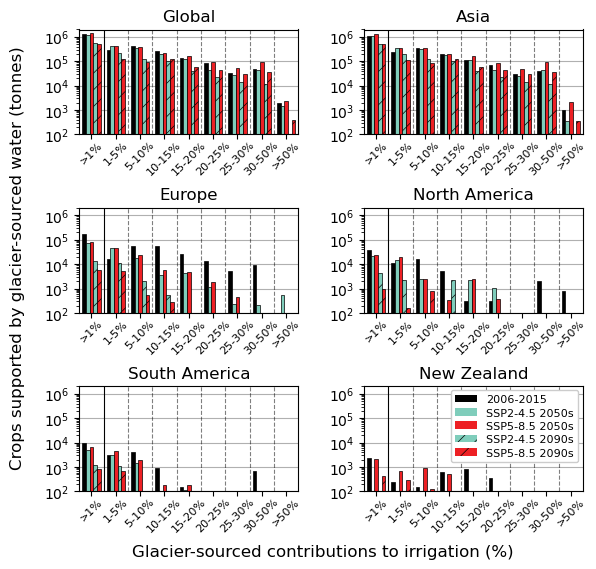

In [22]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
# rois2plot = ['Global']

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6.5, 6), gridspec_kw={'hspace': 0.7, 'wspace':0.3})
axs = axs.flatten()  # make indexing easier

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    dfs = []
    
    # ----- Historical data -----
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yr_cns = [str(x) for x in range(2006, 2016)]
    crop_df['2006-2015'] = crop_df.loc[:,yr_cns].mean(axis=1) / 1e3  # convert to tonnes

    # subset and take difference for bins
    crop_df_hist = crop_df.loc[(crop_df['Name'] == roi) & 
                               (crop_df['elev_threshold'] == 0), ['Name', 'frac', '2006-2015']]
    vals = crop_df_hist['2006-2015']
    bin_vals_df = pd.DataFrame({"bin": ['>1%', '1-5%', '5-10%', '10-15%', '15-20%', '20-25%', '25-30%', '30-50%', '>50%'],
                                "crops": [vals.iloc[0]] + list(vals[:-1].values - vals[1:].values) + [vals.iloc[-1]]})
    dfs.append(bin_vals_df)
    
    # ----- Future data -----
    for yr_start in [2050, 2090]:
        
        for nssp, ssp in enumerate(['ssp245', 'ssp585']):

            irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
            crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)
    
            # decadal mean
            yr_cns = [str(x) for x in range(yr_start, yr_start+10)]
            decade_cn = yr_cns[0] + '-' + yr_cns[-1]
            crop_df[decade_cn] = crop_df.loc[:,yr_cns].mean(axis=1) / 1e3  # convert to tonnes
        
            # subset and take difference for bins
            crop_df_subset = crop_df.loc[(crop_df['Name'] == roi) & 
                                         (crop_df['elev_threshold'] == 0), ['Name', 'frac', decade_cn]]
            vals = crop_df_subset[decade_cn]
            bin_order = ['>1%', '1-5%', '5-10%', '10-15%', '15-20%', '20-25%', '25-30%', '30-50%', '>50%']
            bin_vals_df = pd.DataFrame({"bin": bin_order,
                                        "crops": [vals.iloc[0]] + list(vals[:-1].values - vals[1:].values) + [vals.iloc[-1]]})
            dfs.append(bin_vals_df)

    # ----- PLOT THE DATA -----
    labels = ['2006-2015', 'SSP2-4.5 2050s', 'SSP5-8.5 2050s', 'SSP2-4.5 2090s', 'SSP5-8.5 2090s']
    
    # Combine
    plot_df = pd.concat([df.assign(dataset=label) for df, label in zip(dfs, labels)], ignore_index=True)
    
    # Pivot
    pivot = plot_df.pivot(index="bin", columns="dataset", values="crops")
    pivot = pivot.loc[bin_order]
    pivot = pivot[labels]
    
    # Plot setup
    colors = ['k', ssp_colordict['ssp245'], ssp_colordict['ssp585'], ssp_colordict['ssp245'], ssp_colordict['ssp585']]
    hatches = ['', '', '', '//', '//']  # one pattern per dataset
    
    ax.set_axisbelow(True)
    mpl.rcParams['hatch.linewidth'] = 0.5

    # Plot data
    x = np.arange(pivot.shape[0])
    n = 5
    width = 0.15
    for i, col in enumerate(pivot.columns):
        offset = (i - n/2 + 0.5) * width
        ax.bar(x + offset, pivot[col], width, label=col, color=colors[i],
              edgecolor='k', linewidth=0.5, hatch=hatches[i])
    
    # ----- Vertical separators between bin groups -----
    # Solid line between >1% and 1-10%
    ax.axvline(x=0.5, color='k', linewidth=0.8, linestyle='-')
    
    # Dashed grey lines between all remaining groups
    for xpos in np.arange(1.5, len(bin_order) - 0.5, 1):
        ax.axvline(xpos, color='black', linewidth=0.8, alpha=0.5, linestyle='--')
    
    # ----- Axes formatting -----
    ax.set_ylim(1e2, 2e6)
    ax.set_yscale('log')

    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.grid(axis='y', zorder=1)
    ax.margins(x=0)
    ax.set_xlim(-0.5, len(bin_order) - 0.5)
    
    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=45, ha='center', fontsize=9)
    ax.tick_params(axis='x', labelsize=8, pad=0)

    # Plot labels
    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)

    if roi in ['Australasia']:
        legend_elements = []
        for i in range(len(dfs)):
            legend_elements.append(Patch(facecolor=colors[i], hatch=hatches[i], label=labels[i]))
        
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.3,
                  loc="upper right", 
                  bbox_to_anchor=(0.98, 0.97), 
                  borderaxespad=0.03, frameon=True, facecolor='white', framealpha=1)

# fig.legend(
#     handles=legend_elements,
#     loc='upper center',
#     ncol=5,
#     bbox_to_anchor=(0.46, 0.98),
#     fontsize=8,
#     handlelength=2.5,
#     handletextpad=0.3,
#     columnspacing=0.8,
#     borderpad=0.4
# )

fig.supylabel('Crops supported by glacier-sourced water (tonnes)', x=0.03, size=12, va='center', ha='center')
fig.supxlabel('Glacier-sourced contributions to irrigation (%)', y=0.01, size=12, va='center', ha='center')
    
fig.savefig(paper_fig_fp + 'continent_crops_binned_byperc.png', bbox_inches='tight', dpi=300)
plt.show()

## include SSP3-7.0 for South America

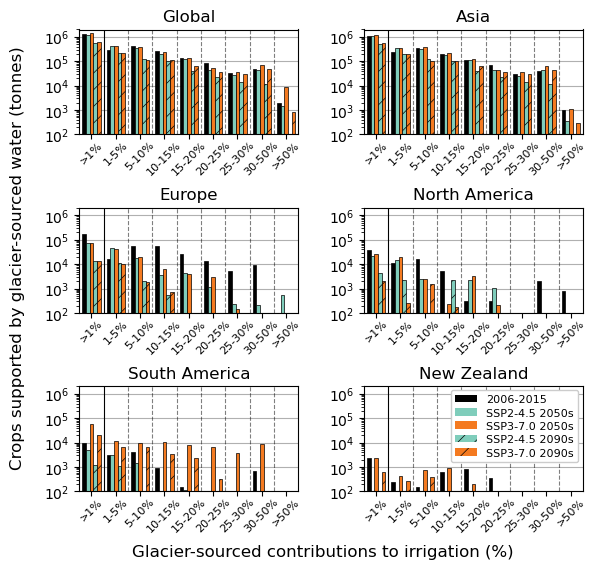

In [23]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
# rois2plot = ['Global']

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6.5, 6), gridspec_kw={'hspace': 0.7, 'wspace':0.3})
axs = axs.flatten()  # make indexing easier

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    dfs = []
    
    # ----- Historical data -----
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yr_cns = [str(x) for x in range(2006, 2016)]
    crop_df['2006-2015'] = crop_df.loc[:,yr_cns].mean(axis=1) / 1e3  # convert to tonnes

    # subset and take difference for bins
    crop_df_hist = crop_df.loc[(crop_df['Name'] == roi) & 
                               (crop_df['elev_threshold'] == 0), ['Name', 'frac', '2006-2015']]
    vals = crop_df_hist['2006-2015']
    bin_vals_df = pd.DataFrame({"bin": ['>1%', '1-5%', '5-10%', '10-15%', '15-20%', '20-25%', '25-30%', '30-50%', '>50%'],
                                "crops": [vals.iloc[0]] + list(vals[:-1].values - vals[1:].values) + [vals.iloc[-1]]})
    dfs.append(bin_vals_df)
    
    # ----- Future data -----
    for yr_start in [2050, 2090]:
        
        for nssp, ssp in enumerate(['ssp245', 'ssp370']):

            irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
            crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)
    
            # decadal mean
            yr_cns = [str(x) for x in range(yr_start, yr_start+10)]
            decade_cn = yr_cns[0] + '-' + yr_cns[-1]
            crop_df[decade_cn] = crop_df.loc[:,yr_cns].mean(axis=1) / 1e3  # convert to tonnes
        
            # subset and take difference for bins
            crop_df_subset = crop_df.loc[(crop_df['Name'] == roi) & 
                                         (crop_df['elev_threshold'] == 0), ['Name', 'frac', decade_cn]]
            vals = crop_df_subset[decade_cn]
            bin_order = ['>1%', '1-5%', '5-10%', '10-15%', '15-20%', '20-25%', '25-30%', '30-50%', '>50%']
            bin_vals_df = pd.DataFrame({"bin": bin_order,
                                        "crops": [vals.iloc[0]] + list(vals[:-1].values - vals[1:].values) + [vals.iloc[-1]]})
            dfs.append(bin_vals_df)

    # ----- PLOT THE DATA -----
    labels = ['2006-2015', 'SSP2-4.5 2050s', 'SSP3-7.0 2050s', 'SSP2-4.5 2090s', 'SSP3-7.0 2090s']
    
    # Combine
    plot_df = pd.concat([df.assign(dataset=label) for df, label in zip(dfs, labels)], ignore_index=True)
    
    # Pivot
    pivot = plot_df.pivot(index="bin", columns="dataset", values="crops")
    pivot = pivot.loc[bin_order]
    pivot = pivot[labels]
    
    # Plot setup
    colors = ['k', ssp_colordict['ssp245'], ssp_colordict['ssp370'], ssp_colordict['ssp245'], ssp_colordict['ssp370']]
    hatches = ['', '', '', '//', '//']  # one pattern per dataset
    
    ax.set_axisbelow(True)
    mpl.rcParams['hatch.linewidth'] = 0.5

    # Plot data
    x = np.arange(pivot.shape[0])
    n = 5
    width = 0.15
    for i, col in enumerate(pivot.columns):
        offset = (i - n/2 + 0.5) * width
        ax.bar(x + offset, pivot[col], width, label=col, color=colors[i],
              edgecolor='k', linewidth=0.5, hatch=hatches[i])
    
    # ----- Vertical separators between bin groups -----
    # Solid line between >1% and 1-10%
    ax.axvline(x=0.5, color='k', linewidth=0.8, linestyle='-')
    
    # Dashed grey lines between all remaining groups
    for xpos in np.arange(1.5, len(bin_order) - 0.5, 1):
        ax.axvline(xpos, color='black', linewidth=0.8, alpha=0.5, linestyle='--')
    
    # ----- Axes formatting -----
    ax.set_ylim(1e2, 2e6)
    ax.set_yscale('log')

    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.grid(axis='y', zorder=1)
    ax.margins(x=0)
    ax.set_xlim(-0.5, len(bin_order) - 0.5)
    
    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=45, ha='center', fontsize=9)
    ax.tick_params(axis='x', labelsize=8, pad=0)

    # Plot labels
    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)

    if roi in ['Australasia']:
        legend_elements = []
        for i in range(len(dfs)):
            legend_elements.append(Patch(facecolor=colors[i], hatch=hatches[i], label=labels[i]))
        
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.3,
                  loc="upper right", 
                  bbox_to_anchor=(0.98, 0.97), 
                  borderaxespad=0.03, frameon=True, facecolor='white', framealpha=1)

# fig.legend(
#     handles=legend_elements,
#     loc='upper center',
#     ncol=5,
#     bbox_to_anchor=(0.46, 0.98),
#     fontsize=8,
#     handlelength=2.5,
#     handletextpad=0.3,
#     columnspacing=0.8,
#     borderpad=0.4
# )

fig.supylabel('Crops supported by glacier-sourced water (tonnes)', x=0.03, size=12, va='center', ha='center')
fig.supxlabel('Glacier-sourced contributions to irrigation (%)', y=0.01, size=12, va='center', ha='center')
    
fig.savefig(paper_fig_fp + 'continent_crops_binned_byperc-ssp245-ssp370.png', bbox_inches='tight', dpi=300)
plt.show()

# Crop time series by region with high-mountain

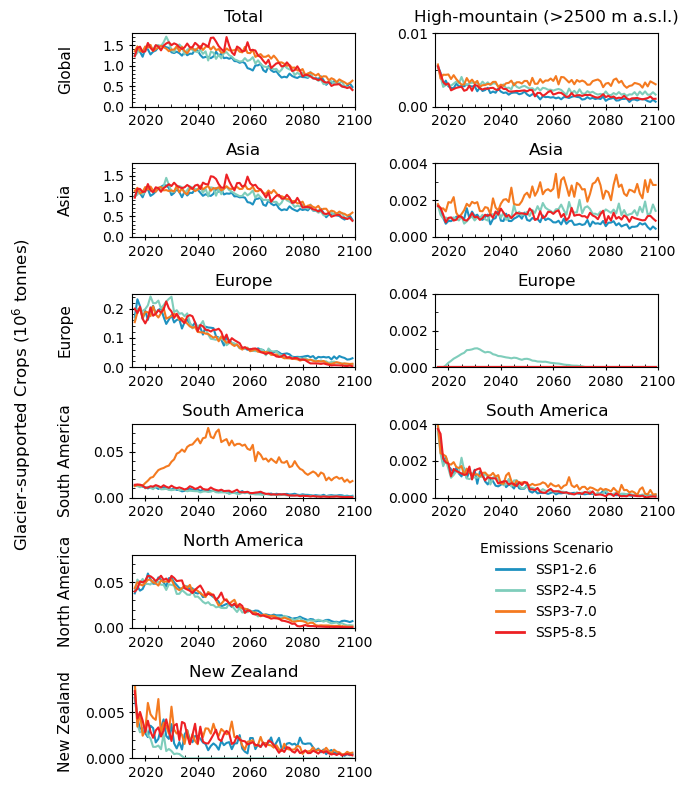

In [24]:
rois2plot = ['Global', 'Asia', 'Europe', 'Central and South America', 'North America', 'Australasia']
# rois2plot = ['Global']

conversion = 1e9 # 1e3 is to tonnes, 1e9 is to millions of tonnes

elev = 2500
plot_hist = False

fig, axs = plt.subplots(nrows=6, ncols=2, figsize=(6.5, 8))

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):

    if plot_hist:
        # ----- Historical -----
        irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
        crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
        yrs_hist = range(1980,2016)
        yr_hist_cns = [str(x) for x in yrs_hist]
    
        # Total
        data_hist = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                     (crop_df_hist['elev_threshold'] == 0) & 
                                     (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:]
        axs[nroi,0].plot(yrs_hist, data_hist/conversion, color='k')

        # High-mountain
        # if roi not in ['North America', 'Australasia']: # no high-mountain population to include
        data_hist_high = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                          (crop_df_hist['elev_threshold'] == elev) & 
                                          (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:]
        axs[nroi,1].plot(yrs_hist, data_hist_high/conversion, color='k')
    
    # ----- FUTURE -----
    for nssp, ssp in enumerate(ssps):

        irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)

        yrs = np.arange(2016,2100)
        yr_cns = [str(x) for x in range(2016,2100)]

        # Total
        data = crop_df.loc[(crop_df['Name'] == roi) & 
                           (crop_df['elev_threshold'] == 0) & 
                           (crop_df['frac'] == 0.01), yr_cns].values[0,:]
        axs[nroi,0].plot(yrs, data/conversion, color=ssp_colordict[ssp])

        # High-mountain
        if roi not in ['North America', 'Australasia']: # no high-mountain population to include
            data_high = crop_df.loc[(crop_df['Name'] == roi) & 
                                    (crop_df['elev_threshold'] == elev) & 
                                    (crop_df['frac'] == 0.01), yr_cns].values[0,:]
            axs[nroi,1].plot(yrs, data_high/conversion, color=ssp_colordict[ssp])
    
    # ----- Labels -----
    for ncol in [0,1]:
        if ncol in [1] and roi in ['North America', 'Australasia']:
            axs[nroi,ncol].set_title(' ')
        elif roi in ['Australasia']:
            axs[nroi,ncol].set_title('New Zealand')
        elif roi in ['Central and South America']:
            axs[nroi,ncol].set_title('South America')
        else:
            axs[nroi,ncol].set_title(roi)

        if plot_hist:
            axs[nroi,ncol].set_xlim(1980,2100)
            axs[nroi,ncol].xaxis.set_major_locator(MultipleLocator(40))
            axs[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(10))
        else:
            axs[nroi,ncol].set_xlim(2015,2100)
            axs[nroi,ncol].xaxis.set_major_locator(MultipleLocator(20))
            axs[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(5))
        
        axs[nroi,ncol].tick_params(axis='both', which='major', direction='inout', length=4)
        axs[nroi,ncol].tick_params(axis='both', which='minor', direction='in', length=2)

    # Total Crops y-scale
    if roi in ['Global', 'Asia']:
        axs[nroi,0].set_ylim(0,1.8)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.5)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.1))
    elif roi in ['Europe']:
        axs[nroi,0].set_ylim(0,0.25)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.1)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.02))
    elif roi in ['North America', 'Central and South America']:
        axs[nroi,0].set_ylim(0,0.08)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.05)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.01))
    else:
        axs[nroi,0].set_ylim(0,0.008)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.005)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.001))

    # High-mountain Crops y-scale
    if roi in ['Global']:
        axs[nroi,1].set_ylim(0,0.01)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.01)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.005))
    elif roi in ['Asia']:
        axs[nroi,1].set_ylim(0,0.004)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.002)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))
    elif roi in ['Europe']:
        axs[nroi,1].set_ylim(0,0.004)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.002)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))
    elif roi in ['Central and South America']:
        axs[nroi,1].set_ylim(0,0.004)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.002)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))

# Remove high-mountain North American & New Zealand axes
axs[4,1].axis('off')
axs[5,1].axis('off')

# Add legend
legend_handles = [Line2D([0], [0], color=ssp_colordict[ssp], lw=2, label=ssp_name_dict[ssp]) for ssp in ssps]

axs[4,1].legend(handles=legend_handles, loc='center', frameon=False, fontsize=10,
                title='Emissions Scenario', title_fontsize=10)

# Add labels on top
axs[0,0].set_title('Total', fontsize=12, pad=8)
axs[0,1].set_title('High-mountain (>2500 m a.s.l.)', fontsize=12, pad=8)

# Row labels on left side
for nroi, roi in enumerate(rois2plot):

    if roi == 'Australasia':
        label = 'New Zealand'
    elif roi == 'Central and South America':
        label = 'South America'
    else:
        label = roi

    axs[nroi,0].text(-0.3, 0.5, label, rotation=90, transform=axs[nroi,0].transAxes, va='center', ha='center', fontsize=11)

fig.text(-0.03, 0.5,'Glacier-supported Crops (10$^{6}$ tonnes)',rotation=90,va='center',ha='center',fontsize=12)

plt.tight_layout()
fig.savefig(paper_fig_fp + 'continent_crops_timeseries_whighmountain_futureonly.png', bbox_inches='tight', dpi=300)
plt.show()

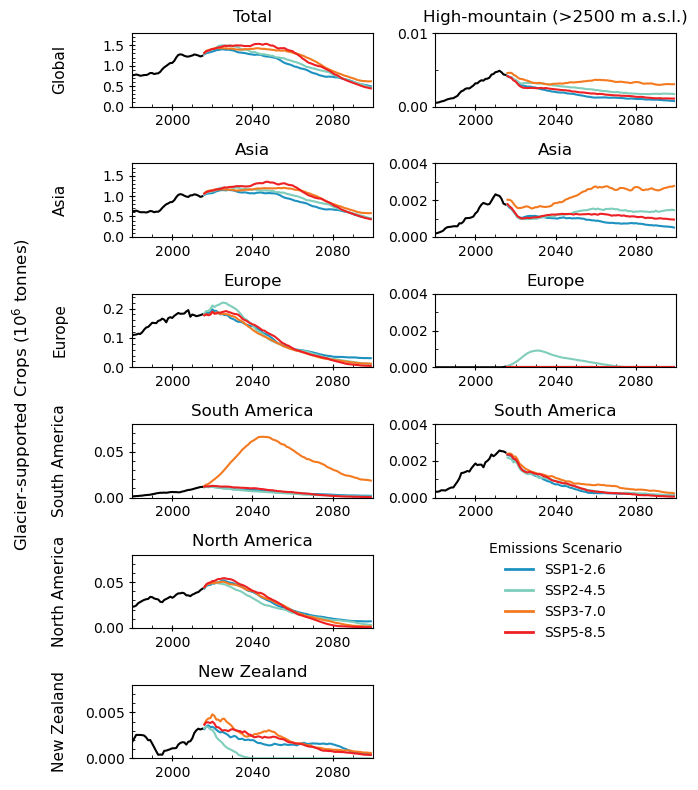

In [25]:
rois2plot = ['Global', 'Asia', 'Europe', 'Central and South America', 'North America', 'Australasia']
# rois2plot = ['Global']

conversion = 1e9 # 1e3 is to tonnes, 1e9 is to millions of tonnes

elev = 2500

fig, axs = plt.subplots(nrows=6, ncols=2, figsize=(6.5, 8))

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):

    # ----- Merge Historical and Future together to get smooth moving averages ----

    # ----- Historical -----
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yrs_hist = range(1980,2016)
    yr_hist_cns = [str(x) for x in yrs_hist]

    # Total
    data_hist = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                 (crop_df_hist['elev_threshold'] == 0) & 
                                 (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:]
    # High-mountain
    data_hist_high = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                      (crop_df_hist['elev_threshold'] == elev) & 
                                      (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:]
    
    for ssp in ssps2plot:
        # ----- Future -----
        irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
        yrs = range(2016,2100)
        yr_cns = [str(x) for x in yrs]
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)

        # Total future
        data = crop_df.loc[(crop_df['Name'] == roi) & 
                           (crop_df['elev_threshold'] == 0) & 
                                  (crop_df['frac'] == 0.01), yr_cns].values[0,:]
        # High-mountain future
        data_high = crop_df.loc[(crop_df['Name'] == roi) & 
                                (crop_df['elev_threshold'] == elev) & 
                                (crop_df['frac'] == 0.01), yr_cns].values[0,:]
        
        data_hist_wssp = np.concatenate((data_hist, data)) / conversion
        data_hist_wssp_high = np.concatenate((data_hist_high, data_high)) / conversion
        
        data_hist_wssp_movingavg = uniform_filter(data_hist_wssp, size=(11), mode='nearest')
        data_hist_wssp_high_movingavg = uniform_filter(data_hist_wssp_high, size=(11), mode='nearest')

        # Plot historical
        if ssp in ['ssp245']:
            axs[nroi,0].plot(yrs_hist, data_hist_wssp_movingavg[0:data_hist.shape[0]], color='k')
            if roi not in ['North America', 'Australasia']: # no high-mountain in these regions
                axs[nroi,1].plot(yrs_hist, data_hist_wssp_high_movingavg[0:data_hist.shape[0]], color='k')

        # Plot future
        axs[nroi,0].plot(yrs, data_hist_wssp_movingavg[data_hist.shape[0]:], color=ssp_colordict[ssp])
        if roi not in ['North America', 'Australasia']: # no high-mountain these regions
            axs[nroi,1].plot(yrs, data_hist_wssp_high_movingavg[data_hist.shape[0]:], color=ssp_colordict[ssp])
    
    # ----- Labels -----
    for ncol in [0,1]:
        if ncol in [1] and roi in ['North America', 'Australasia']:
            axs[nroi,ncol].set_title(' ')
        elif roi in ['Australasia']:
            axs[nroi,ncol].set_title('New Zealand')
        elif roi in ['Central and South America']:
            axs[nroi,ncol].set_title('South America')
        else:
            axs[nroi,ncol].set_title(roi)

        axs[nroi,ncol].set_xlim(1980,2100)
        axs[nroi,ncol].xaxis.set_major_locator(MultipleLocator(40))
        axs[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(10))
        
        axs[nroi,ncol].tick_params(axis='both', which='major', direction='inout', length=4)
        axs[nroi,ncol].tick_params(axis='both', which='minor', direction='in', length=2)

    # Total Crops y-scale
    if roi in ['Global', 'Asia']:
        axs[nroi,0].set_ylim(0,1.8)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.5)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.1))
    elif roi in ['Europe']:
        axs[nroi,0].set_ylim(0,0.25)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.1)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.02))
    elif roi in ['North America', 'Central and South America']:
        axs[nroi,0].set_ylim(0,0.08)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.05)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.01))
    else:
        axs[nroi,0].set_ylim(0,0.008)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.005)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.001))

    # High-mountain Crops y-scale
    if roi in ['Global']:
        axs[nroi,1].set_ylim(0,0.01)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.01)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.005))
    elif roi in ['Asia']:
        axs[nroi,1].set_ylim(0,0.004)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.002)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))
    elif roi in ['Europe']:
        axs[nroi,1].set_ylim(0,0.004)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.002)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))
    elif roi in ['Central and South America']:
        axs[nroi,1].set_ylim(0,0.004)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.002)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))

# Remove high-mountain North American & New Zealand axes
axs[4,1].axis('off')
axs[5,1].axis('off')

# Add legend
legend_handles = [Line2D([0], [0], color=ssp_colordict[ssp], lw=2, label=ssp_name_dict[ssp]) for ssp in ssps]

axs[4,1].legend(handles=legend_handles, loc='center', frameon=False, fontsize=10,
                title='Emissions Scenario', title_fontsize=10)

# Add labels on top
axs[0,0].set_title('Total', fontsize=12, pad=8)
axs[0,1].set_title('High-mountain (>2500 m a.s.l.)', fontsize=12, pad=8)

# Row labels on left side
for nroi, roi in enumerate(rois2plot):

    if roi == 'Australasia':
        label = 'New Zealand'
    elif roi == 'Central and South America':
        label = 'South America'
    else:
        label = roi

    axs[nroi,0].text(-0.3, 0.5, label, rotation=90, transform=axs[nroi,0].transAxes, va='center', ha='center', fontsize=11)

fig.text(-0.03, 0.5,'Glacier-supported Crops (10$^{6}$ tonnes)',rotation=90,va='center',ha='center',fontsize=12)

plt.tight_layout()
fig.savefig(paper_fig_fp + 'figS9_continent_crops_timeseries_whighmountain.png', bbox_inches='tight', dpi=300)
plt.show()

### Log scale plot

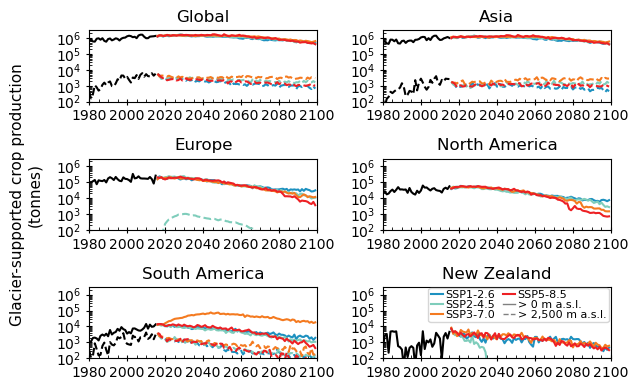

In [26]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

conversion = 1e3 # kg to tonnes

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6.5, 4))
axs = axs.flatten()  # make indexing easier

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    # ----- HISTORICAL -----
    irrProd_cont_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
    crop_df_hist = pd.read_csv(irrProd_cont_fp + irrProd_cont_fn_hist)
    yrs_hist = range(1980,2016)
    yr_hist_cns = [str(x) for x in yrs_hist]

    # Total
    data_hist = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                 (crop_df_hist['elev_threshold'] == 0) & 
                                 (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:]
    ax.plot(yrs_hist, data_hist/conversion, color='k')

    # High-mountain
    # if roi not in ['North America', 'Australasia']: # no high-mountain population to include
    data_hist_high = crop_df_hist.loc[(crop_df_hist['Name'] == roi) & 
                                      (crop_df_hist['elev_threshold'] == elev) & 
                                      (crop_df_hist['frac'] == 0.01), yr_hist_cns].values[0,:]
    ax.plot(yrs_hist, data_hist_high/conversion, color='k', linestyle='--')

    # ----- FUTURE -----
    for nssp, ssp in enumerate(ssps):
        irrProd_med_fn = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
        crop_df = pd.read_csv(irrProd_cont_fp + irrProd_med_fn)

        yrs = np.arange(2016,2100)
        yr_cns = [str(x) for x in range(2016,2100)]

        # Total
        data = crop_df.loc[(crop_df['Name'] == roi) & 
                           (crop_df['elev_threshold'] == 0) & 
                           (crop_df['frac'] == 0.01), yr_cns].values[0,:]
        ax.plot(yrs, data/conversion, color=ssp_colordict[ssp])

        # High-mountain
        data_high = crop_df.loc[(crop_df['Name'] == roi) & 
                                (crop_df['elev_threshold'] == elev) & 
                                (crop_df['frac'] == 0.01), yr_cns].values[0,:]
        ax.plot(yrs, data_high/conversion, color=ssp_colordict[ssp], linestyle='--')

    # ----- LABELS -----

    ax.set_xlim(1980,2100)

    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    ax.tick_params(axis='both', which='major', direction='inout', length=4)
    ax.tick_params(axis='both', which='minor', direction='in', length=2)

    ax.set_yscale('log')
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks
    ax.set_ylim(1e2, 3e6)

    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)

    if roi in ['Australasia']:
        legend_elements = []
        for ssp in ssps:
            legend_elements.append(Line2D([0], [0], color=ssp_colordict[ssp], linestyle='-', label=ssp_name_dict[ssp]))
        # high mountain part
        legend_elements.append(Line2D([0], [0], color='grey', linestyle='-', 
                               label='> 0 m a.s.l.', linewidth=1))
        legend_elements.append(Line2D([0], [0], color='grey', linestyle='--', 
                               label='> 2,500 m a.s.l.', linewidth=1))
        # # spacer
        # legend_elements.append(
        #     Line2D([], [], linestyle='none', label='')
        # )
            
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.0, handlelength=1.1, handletextpad=0.2, ncol=2,
                  loc="upper right", bbox_to_anchor=(0.99, 0.99), 
                  borderaxespad=0.01, borderpad=0.2, columnspacing=0.75)

fig.supylabel('Glacier-supported crop production\n(tonnes)', x=0.05, size=11, va='center', ha='center')
    
plt.tight_layout()
fig.savefig(paper_fig_fp + 'continent_highmountain_crop_timeseries.png', bbox_inches='tight', dpi=300)
plt.show()